<a href="https://colab.research.google.com/github/nattaponm/Teach_Tdating_strom_tracks_HID_CloudProperties/blob/main/notebooks/04_dualpol_hid_doppler_along_tracks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 4: HID, dual-pol และ Doppler ตามเส้นทางเมฆ
### Hydrometeor classes, KDP/ZDR and dealiased Doppler velocity sampled inside tracked cells: life cycle, classes and relationships

⏱️ เวลาเรียนโดยประมาณ **90 นาที** | ต้องผ่าน: Notebook 3 (และแนะนำ repo *Teach_HID_Doppler_KKN_summerStorm*)

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **ดึงค่า HID, KDP, ZDR, Doppler (dealiased), divergence และ EDR ภายในเซลล์** ที่ติดตามด้วย T-DaTing — เฉพาะเวลาที่วัดจริง
2. **สร้าง composite ตามวงจรชีวิต** (อายุสัมพัทธ์ τ) เพื่อดูว่าลูกเห็บ ฝนหนัก และ outflow เกิดในช่วงใดของชีวิตพายุ
3. **เปรียบเทียบตัวแปร dual-pol/Doppler ระหว่างกลุ่มพายุ** (อายุ ขนาด) ด้วย boxplot และสถิติ
4. **หาความสัมพันธ์ระหว่างขนาด/อายุ/ความยาวเส้นทาง กับ dual-pol และ Doppler** และตรวจว่าผลขึ้นกับ Δt หรือไม่
5. **ระวังปัจจัยแทรกซ้อน** เช่น ระยะจากเรดาร์ (ความสูงลำคลื่น) ที่มีผลต่อทุกตัวแปร

## 📖 1. แนวคิดและสมการ

### 1.1 ตัวแปรที่ดึงจากแต่ละเซลล์ (ภาพจริงทุก 15 นาที)
| ตัวแปร | นิยาม | ความหมาย |
|---|---|---|
| `hail_col_km2` | พื้นที่ที่คอลัมน์มี MH หรือ IH/HDG **และ** Z ≥ 40 dBZ | ขนาดพื้นที่ลูกเห็บ/graupel หนาแน่น |
| `hail_low_frac` | สัดส่วน pixel มุมยก 0.48° ที่เป็น MH/IH-HDG | ลูกเห็บใกล้ระดับต่ำ (กำลังตกลงมา) |
| `graupel_up_frac` | สัดส่วน RP ในมุมยก 2.39° และ 3.39° | การ riming ในระดับบน (updraft ที่มีน้ำเย็นจัด) |
| `rain_low_frac`, `ice_up_frac` | สัดส่วน LR+RN (ล่าง), AG+CR+VI (บน) | โครงสร้างฝน–น้ำแข็ง |
| `KDP95`, `ZDR90` | เปอร์เซ็นไทล์ 95 ของ KDP (ค่าสูงสุดในคอลัมน์), 90 ของ ZDR | น้ำเหลวมาก/ฝนหนัก, เม็ดฝนใหญ่ |
| `V95`, `dV` | \|V\| p95 และ $V_{max} - V_{min}$ (มุม 0.48°, dealiased) | ความแรงลม, ลายเซ็น outflow/rotation |
| `DIVmax`, `AZSmax` | divergence และ \|azimuthal shear\| สูงสุด (10⁻³ s⁻¹) | downburst, การหมุน |
| `EDR95` | EDR$^{1/3}$ p95 (PyTDA) | ความปั่นป่วน |

$$ f_c = \frac{N_c}{N_{\mathrm{classified}}},\qquad \Delta V = V_{max} - V_{min} $$

### 1.2 Composite ตามวงจรชีวิต
เส้นทางมีอายุต่างกัน จึงแปลงเวลาเป็น **อายุสัมพัทธ์**
$$ \tau = \frac{t - t_{start}}{t_{end} - t_{start}} \in [0, 1] $$
แล้วรวมทุกเส้นทางในช่วง τ: ต้น (0–⅓), กลาง (⅓–⅔), ปลาย (⅔–1)
สมมติฐานตามแบบจำลองพายุฟ้าคะนอง: graupel/ลูกเห็บในระดับบน **สูงสุดช่วงกลาง** → ลูกเห็บตก/downdraft → **outflow (divergence) ช่วงกลาง–ปลาย**

### 1.3 ข้อควรระวัง
- เซลล์ที่ **ไกลเรดาร์** ลำคลื่นสูง → เห็นน้ำแข็งมากขึ้น เห็นลมใกล้พื้นน้อยลง → ทุกตัวแปรขึ้นกับระยะ
- HID ของเซลล์ที่ระยะ > 150 km มีความไม่แน่นอนสูง (repo HID NB1, NB5)

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–4 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_Tdating_strom_tracks_HID_CloudProperties"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q pysteps==1.21.5 arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio scikit-image
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "track_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")
DER = os.path.join(DATA, "derived")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import track_tools as tt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_Tdating_strom_tracks_HID_CloudProperties/data


In [2]:
terr = tt.load_terrain(os.path.join(DER, "KKN_20240503_terrain_1km.nc"))
polar, ptimes = tt.load_polar_grid(os.path.join(DER, "KKN_20240503_polar_15min.nc"))
beam = terr["beam_h0_km"]
SETS = {}
for dt in (15, 10, 5):
    S = tt.load_set(DER, tt.MAIN[dt])
    C = tt.cell_table(S["labels"], S["Z"], S["times"], S["meta"], terrain=terr, polar=polar, polar_times=ptimes, beam=beam)
    C = tt.add_motion(C, terr, S["meta"])
    T = tt.track_table(C)
    keep = T.index[T.lifetime_min >= 30]
    SETS[dt] = {**S, "C": C[C.track_id.isin(keep)].copy(), "T": tt.classify_tracks(T.loc[keep])}
meta = SETS[15]["meta"]
reports = kt.load_reports(DATA, meta)
date0 = SETS[15]["times"][0].normalize()
print("polar products:", list(polar), "|", len(ptimes), "เวลา")
VARS = ["hail_col_km2", "hail_low_frac", "graupel_up_frac", "KDP95", "ZDR90", "V95", "dV", "DIVmax", "AZSmax", "EDR95"]
SETS[15]["C"].loc[SETS[15]["C"].observed, VARS].describe().round(2)

polar products: ['Zc', 'vel', 'div', 'azshear', 'edr', 'kdp', 'zdr', 'hid_s0', 'hid_s1', 'hid_s2', 'hid_s3', 'hail_col', 'graupel_col'] | 49 เวลา


,hail_col_km2,hail_low_frac,graupel_up_frac,KDP95,ZDR90,V95,dV,DIVmax,AZSmax,EDR95
count,229.00,229.00,213.00,229.00,229.00,219.00,217.00,209.00,202.00,201.00
mean,39.76,0.25,0.16,1.38,3.40,7.22,10.77,1.31,1.18,0.18
std,42.58,0.22,0.14,1.00,1.22,3.35,6.44,1.46,1.54,0.03
min,0.00,0.00,0.00,0.00,0.80,1.99,0.90,-2.95,0.03,0.10
25%,10.00,0.06,0.02,0.61,2.47,5.00,5.60,0.43,0.43,0.16
50%,26.00,0.20,0.15,1.18,3.41,6.75,9.20,0.91,0.76,0.18
75%,56.00,0.42,0.26,1.93,4.49,8.43,15.50,1.84,1.39,0.20
max,247.00,0.88,0.65,4.53,5.85,24.38,34.52,8.32,16.29,0.36


## 🗺️ 3. ดึงค่าจากเซลล์อย่างไร: ตัวอย่าง 09:30 UTC รอบนากลาง

บันทึกรูปแล้ว: figures/nb4_extraction_example.png, figures/nb4_extraction_example.pdf


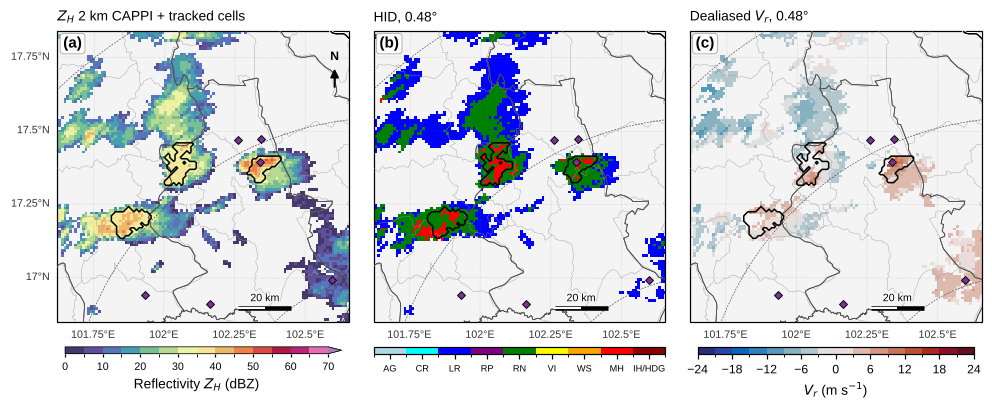

,track_id,area_km2,Zmax,hail_col_km2,hail_low_frac,KDP95,V95,dV,DIVmax,EDR95,range_km
111,37,155.0,45.0,34.0,0.04,0.37,7.18,15.00,0.56,0.14,215.91
115,38,71.0,51.4,54.0,0.23,1.06,13.86,12.16,2.05,0.19,111.68
122,39,104.0,45.0,44.0,0.32,1.70,5.86,6.40,1.07,0.17,126.11
136,45,58.0,43.5,13.0,0.10,1.29,9.84,18.56,7.22,0.14,185.52
145,46,171.0,48.2,93.0,0.64,1.99,4.32,10.10,1.91,0.19,99.69
151,48,75.0,54.0,27.0,0.24,0.93,4.84,8.30,1.12,NaN,223.26
159,50,40.0,46.5,14.0,0.15,1.18,5.90,3.80,NaN,0.13,191.93
162,51,105.0,52.3,79.0,0.74,2.37,5.68,14.80,5.09,0.19,104.70
167,52,136.0,55.5,38.0,0.31,0.98,3.60,7.00,0.43,NaN,226.74
170,53,104.0,43.0,71.0,0.56,2.62,8.18,15.86,1.66,0.18,128.68


In [3]:
import matplotlib as mpl
from utils import polar_tools as pt
S = SETS[15]
i = list(S["times"]).index(date0 + pd.Timedelta(hours=9, minutes=30))
j = list(ptimes).index(date0 + pd.Timedelta(hours=9, minutes=30))
s_nk = kt.site(reports, "Na Klang")
ZB = kt.box_around(meta, s_nk["lon"] - 0.2, s_nk["lat"] - 0.05, 55)
fig, axs = mp.map_panels(1, 3, meta, panel_width=3.0, zoom=ZB)
crs = mp.get_crs(meta)
hid = np.where(polar["hid_s0"][j] > 0, polar["hid_s0"][j], np.nan)
cm_h, nm_h = pt.hid_cmap_norm()
im0 = mp.radar_map(axs[0], S["Z"][i], meta, zoom=ZB, title="$Z_H$ 2 km CAPPI + tracked cells")
im1 = mp.field_map(axs[1], hid, meta, cmap=cm_h, zoom=ZB, title="HID, 0.48°", gridline_labels=("bottom",), extend="neither")
im1.set_norm(nm_h)
cmv = pt.field_cmaps()["V"]
im2 = mp.field_map(axs[2], polar["vel"][j], meta, cmap=cmv[0], zoom=ZB, title="Dealiased $V_r$, 0.48°", gridline_labels=("bottom",))
im2.set_norm(cmv[1])
lab = S["labels"][i]
for ax in axs:
    for k in np.unique(lab[lab > 0]):
        ax.contour(meta["x"], meta["y"], (lab == k).astype(float), levels=[0.5], colors="k", linewidths=1.0, transform=crs, zorder=8)
    mp.add_reports(ax, reports, legend=False, ms=4)
mp.add_colorbar(fig, im0, axs[0], shrink=0.9)
cb = fig.colorbar(im1, ax=axs[1], orientation="horizontal", shrink=0.95, pad=0.02, aspect=40, ticks=np.arange(1, 10))
cb.set_ticklabels(tt.HID_NAMES[1:]); cb.ax.tick_params(labelsize=6)
fig.colorbar(im2, ax=axs[2], orientation="horizontal", shrink=0.9, pad=0.02, aspect=40, label="$V_r$ (m s$^{-1}$)")
mp.panel_labels(axs)
mp.save_figure(fig, "nb4_extraction_example")
plt.show()
cells_now = S["C"][S["C"].time == S["times"][i]]
cells_now[["track_id", "area_km2", "Zmax", "hail_col_km2", "hail_low_frac", "KDP95", "V95", "dV", "DIVmax", "EDR95", "range_km"]].round(2)

## 🔄 4. Composite ตามวงจรชีวิตของพายุ (เส้นทางอายุ ≥ 45 นาที)

บันทึกรูปแล้ว: figures/nb4_lifecycle_composite.png, figures/nb4_lifecycle_composite.pdf


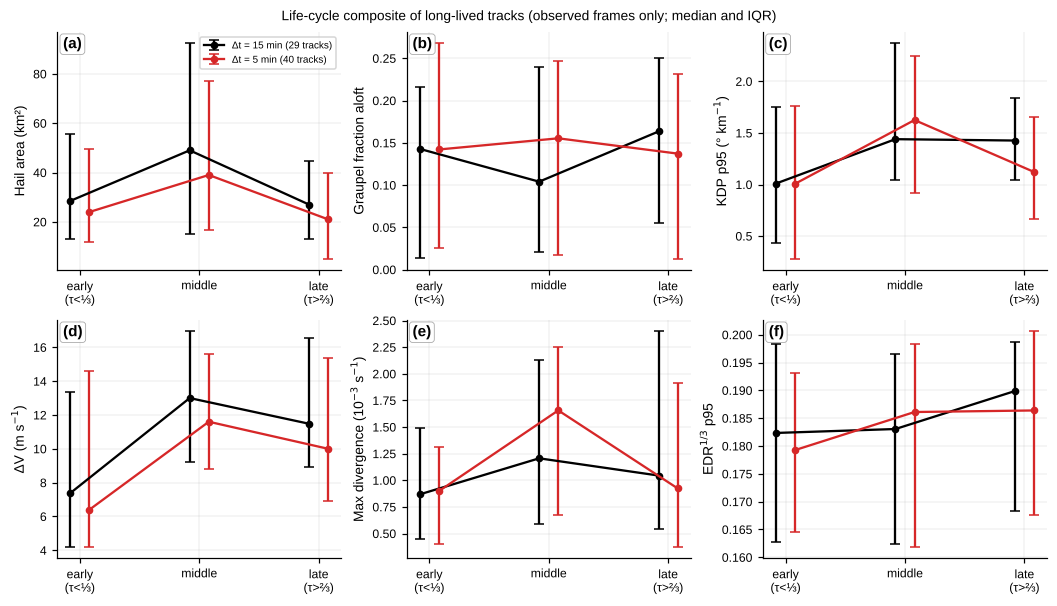

,hail_col_km2,graupel_up_frac,KDP95,dV,DIVmax,EDR95
stage,,,,,,
early,28.5,0.14,1.01,7.38,0.87,0.18
middle,49.0,0.10,1.44,13.00,1.21,0.18
late,27.0,0.16,1.43,11.48,1.04,0.19


In [4]:
def composite(C, T, min_life=45):
    long_ids = T.index[T.lifetime_min >= min_life]
    D = C[C.track_id.isin(long_ids) & C.observed].copy()
    st_ = T.loc[D.track_id, "start"].values
    en_ = T.loc[D.track_id, "end"].values
    D["tau"] = (D["time"].values - st_) / (en_ - st_)
    D["stage"] = pd.cut(D["tau"], [-0.01, 1 / 3, 2 / 3, 1.01], labels=["early", "middle", "late"])
    return D

comp_vars = [("hail_col_km2", "Hail area (km²)"), ("graupel_up_frac", "Graupel fraction aloft"),
             ("KDP95", "KDP p95 (° km$^{-1}$)"), ("dV", "ΔV (m s$^{-1}$)"), ("DIVmax", "Max divergence (10$^{-3}$ s$^{-1}$)"),
             ("EDR95", "EDR$^{1/3}$ p95")]
fig, axs = plt.subplots(2, 3, figsize=(9.5, 5.4), layout="constrained")
cols = {15: "k", 5: "tab:red"}
COMP = {}
for dt in (15, 5):
    D = composite(SETS[dt]["C"], SETS[dt]["T"])
    COMP[dt] = D
    for ax, (v, lab) in zip(axs.ravel(), comp_vars):
        med = D.groupby("stage", observed=False)[v].median()
        q1 = D.groupby("stage", observed=False)[v].quantile(0.25)
        q3 = D.groupby("stage", observed=False)[v].quantile(0.75)
        x = np.arange(3) + (0.08 if dt == 5 else -0.08)
        ax.errorbar(x, med, yerr=[med - q1, q3 - med], fmt="o-", color=cols[dt], capsize=3, ms=4,
                    label=f"Δt = {dt} min ({D.track_id.nunique()} tracks)")
        ax.set_xticks(range(3), ["early\n(τ<⅓)", "middle", "late\n(τ>⅔)"]); ax.set_ylabel(lab); ax.grid(lw=0.3, alpha=0.5)
axs[0, 0].legend(fontsize=6.5)
mp.panel_labels(axs.ravel())
fig.suptitle("Life-cycle composite of long-lived tracks (observed frames only; median and IQR)", fontsize=9)
mp.save_figure(fig, "nb4_lifecycle_composite")
plt.show()
COMP[15].groupby("stage", observed=False)[[v for v, _ in comp_vars]].median().round(2)

**อ่านกราฟ:** ดูว่าตัวแปรใดสูงสุดช่วง **กลาง** ของชีวิต (ระยะเจริญเต็มที่) และตัวแปรใดเพิ่มขึ้นช่วง **ปลาย** (ระยะสลาย, downdraft เด่น)
- ในพายุ 3 พ.ค. **พื้นที่ลูกเห็บ, KDP, ΔV และ divergence สูงสุดช่วงกลาง** ของชีวิตทั้งสอง Δt — สอดคล้องกับแบบจำลองระยะเจริญเต็มที่
- **graupel ระดับบน** และ **EDR** ไม่มีรูปแบบชัดเจน (เปลี่ยนน้อยและไม่สอดคล้องกันระหว่าง Δt)
- ที่ Δt = 5 นาที เวลาเริ่ม–จบของเส้นทางแม่นขึ้น (นิยาม τ ดีขึ้น) แต่ค่าที่ใช้ยังมาจากภาพจริงทุก 15 นาทีเท่านั้น
- ช่วงระหว่างควอไทล์ (error bar) กว้าง → พายุแต่ละลูกต่างกันมาก ต้องมีตัวอย่างหลายพายุ/หลายวันจึงจะสรุปได้มั่นคง

## 📊 5. เปรียบเทียบตามกลุ่มอายุและขนาด (Δt = 15 นาที)

บันทึกรูปแล้ว: figures/nb4_boxplots_dualpol_doppler.png, figures/nb4_boxplots_dualpol_doppler.pdf


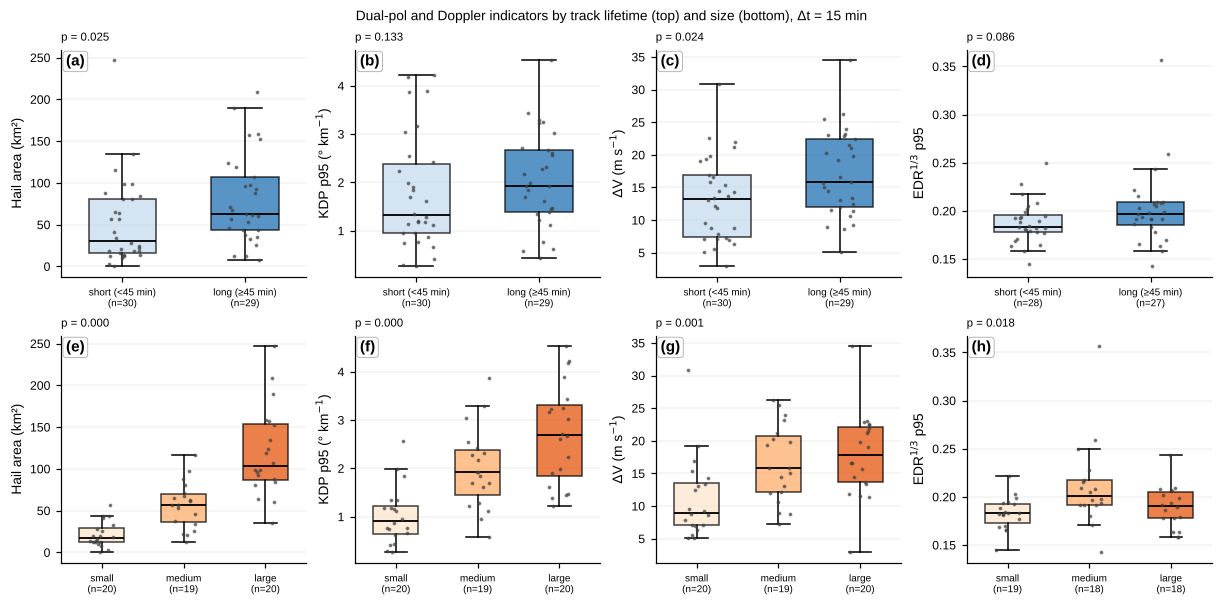

In [5]:
T15 = SETS[15]["T"]
panel_vars = [("hail_col_km2", "Hail area (km²)"), ("KDP95", "KDP p95 (° km$^{-1}$)"),
              ("dV", "ΔV (m s$^{-1}$)"), ("EDR95", "EDR$^{1/3}$ p95")]
fig, axs = plt.subplots(2, 4, figsize=(11, 5.4), layout="constrained")
for c, (v, lab) in enumerate(panel_vars):
    for r, (grp, colors) in enumerate((("life_class", ["#c6dbef", "#2171b5"]), ("size_class", ["#fee6ce", "#fdae6b", "#e6550d"]))):
        ax = axs[r, c]
        tt.boxplot_groups(ax, T15, v, grp, colors=colors, ylabel=lab)
        H, p, _ = tt.kruskal_dunn(T15, v, grp)
        ax.set_title(f"p = {p:.3f}", loc="left", fontsize=7.5)
        ax.tick_params(axis="x", labelsize=6.5)
mp.panel_labels(axs.ravel())
fig.suptitle("Dual-pol and Doppler indicators by track lifetime (top) and size (bottom), Δt = 15 min", fontsize=9)
mp.save_figure(fig, "nb4_boxplots_dualpol_doppler")
plt.show()

## 🔗 6. ความสัมพันธ์ระดับเส้นทาง: ขนาด/อายุ/ความยาว กับ dual-pol และ Doppler ในแต่ละ Δt

บันทึกรูปแล้ว: figures/nb4_correlation_by_resolution.png, figures/nb4_correlation_by_resolution.pdf


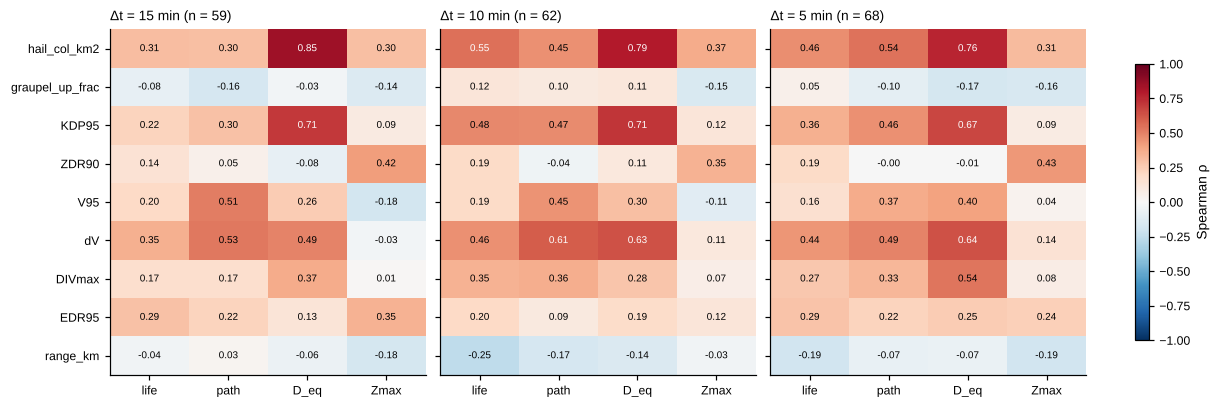

In [6]:
from scipy.stats import spearmanr
X = ["lifetime_min", "path_km", "deq_max", "Zmax_obs"]
Y = ["hail_col_km2", "graupel_up_frac", "KDP95", "ZDR90", "V95", "dV", "DIVmax", "EDR95", "range_km"]
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6), layout="constrained", sharey=True)
RHO = {}
for ax, dt in zip(axs, (15, 10, 5)):
    T = SETS[dt]["T"]
    M = np.array([[spearmanr(T[x], T[y], nan_policy="omit")[0] for y in Y] for x in X])
    RHO[dt] = pd.DataFrame(M, index=X, columns=Y)
    im = ax.imshow(M.T, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(X)), ["life", "path", "D_eq", "Zmax"], rotation=0)
    ax.set_yticks(range(len(Y)), Y)
    for a in range(len(X)):
        for b in range(len(Y)):
            ax.text(a, b, f"{M[a, b]:.2f}", ha="center", va="center", fontsize=6.5, color="w" if abs(M[a, b]) > 0.55 else "k")
    ax.set_title(f"Δt = {dt} min (n = {len(T)})", loc="left", fontsize=9)
fig.colorbar(im, ax=list(axs), shrink=0.8, label="Spearman ρ")
mp.save_figure(fig, "nb4_correlation_by_resolution")
plt.show()

- ความสัมพันธ์ที่ **เห็นทุก Δt** (สีเดียวกันทั้งสามแผง) น่าเชื่อถือกว่าความสัมพันธ์ที่ปรากฏเฉพาะบางความละเอียด
- แถว `range_km`: ถ้าตัวแปรใดสัมพันธ์กับระยะมาก ความสัมพันธ์ของตัวแปรนั้นกับขนาด/อายุอาจเป็นผลของ **ตำแหน่งพายุ** ไม่ใช่ฟิสิกส์ (ทดสอบในแบบฝึกหัด 4.3)

## 🎯 7. พายุนากลาง: HID และ Doppler ตามเวลา

บันทึกรูปแล้ว: figures/nb4_naklang_dualpol_doppler.png, figures/nb4_naklang_dualpol_doppler.pdf


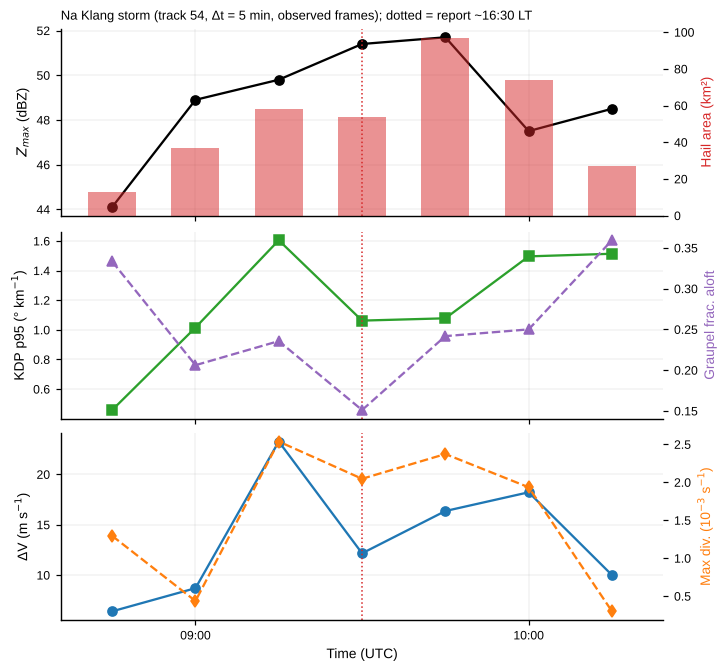

In [7]:
S = SETS[5]
near = tt.tracks_near(S["T"], S["C"], s_nk["lon"], s_nk["lat"], t_ref=kt.report_time_utc(s_nk, date0.to_pydatetime()),
                      radius_km=15, window_min=45, meta=meta)
tid = int(near.index[0])
g = S["C"].query("track_id == @tid and observed")
fig, axs = plt.subplots(3, 1, figsize=(6.5, 6), sharex=True, layout="constrained")
axs[0].plot(g.time, g.Zmax, "o-", color="k", label="Zmax"); axs[0].set_ylabel("$Z_{max}$ (dBZ)")
a2 = axs[0].twinx(); a2.bar(g.time, g.hail_col_km2, width=0.006, color="tab:red", alpha=0.5); a2.set_ylabel("Hail area (km²)", color="tab:red")
axs[1].plot(g.time, g.KDP95, "s-", color="tab:green", label="KDP p95"); axs[1].set_ylabel("KDP p95 (° km$^{-1}$)")
a3 = axs[1].twinx(); a3.plot(g.time, g.graupel_up_frac, "^--", color="tab:purple"); a3.set_ylabel("Graupel frac. aloft", color="tab:purple")
axs[2].plot(g.time, g.dV, "o-", color="tab:blue", label="ΔV"); axs[2].set_ylabel("ΔV (m s$^{-1}$)")
a4 = axs[2].twinx(); a4.plot(g.time, g.DIVmax, "d--", color="tab:orange"); a4.set_ylabel("Max div. (10$^{-3}$ s$^{-1}$)", color="tab:orange")
t_rep = kt.report_time_utc(s_nk, date0.to_pydatetime())
for ax in axs:
    ax.axvline(t_rep, color="tab:red", ls=":", lw=1); ax.grid(lw=0.3, alpha=0.5)
axs[0].set_title(f"Na Klang storm (track {tid}, Δt = 5 min, observed frames); dotted = report ~16:30 LT", loc="left", fontsize=8.5)
mp.time_axis(axs[2], interval_h=1, local_top=False)
mp.save_figure(fig, "nb4_naklang_dualpol_doppler")
plt.show()

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 4.1: พายุอายุยาวมีลูกเห็บมากกว่าหรือไม่?
เปรียบเทียบ `hail_col_km2` และ `hail_low_frac` ระหว่าง `life_class` สั้น/ยาว ในทั้งสาม Δt ด้วย Mann–Whitney U และ Cliff's δ
แล้วทำ boxplot แบบเดียวกับ section 5 แต่มี 6 กลุ่ม (3 Δt × 2 กลุ่มอายุ)

**คำถาม:** ข้อสรุปเหมือนกันทุก Δt หรือไม่? `hail_col_km2` (พื้นที่) กับ `hail_low_frac` (สัดส่วน) ตอบคำถามต่างกันอย่างไร

<details>
<summary><b>💡 คำใบ้</b></summary>

- รวมตาราง: `pd.concat([SETS[d]["T"].assign(dt=d) for d in (15, 10, 5)])`
- `from scipy.stats import mannwhitneyu`

</details>

In [8]:
# ✍️ แบบฝึกหัด 4.1 — เขียนโค้ดของคุณที่นี่

                      median_long  median_short  cliffs_delta      p  n_long  \
variable      dt_min                                                           
hail_col_km2  15           63.000        31.000         0.339  0.026      29   
hail_low_frac 15            0.469         0.310         0.285  0.061      29   
hail_col_km2  10           47.000        26.000         0.531  0.000      25   
hail_low_frac 10            0.403         0.241         0.336  0.026      25   
hail_col_km2  5            55.000        28.500         0.326  0.023      40   
hail_low_frac 5             0.425         0.408        -0.032  0.827      40   

                      n_short  
variable      dt_min           
hail_col_km2  15           30  
hail_low_frac 15           30  
hail_col_km2  10           37  
hail_low_frac 10           37  
hail_col_km2  5            28  
hail_low_frac 5            28  


บันทึกรูปแล้ว: figures/nb4_ex41_hail_lifeclass.png, figures/nb4_ex41_hail_lifeclass.pdf


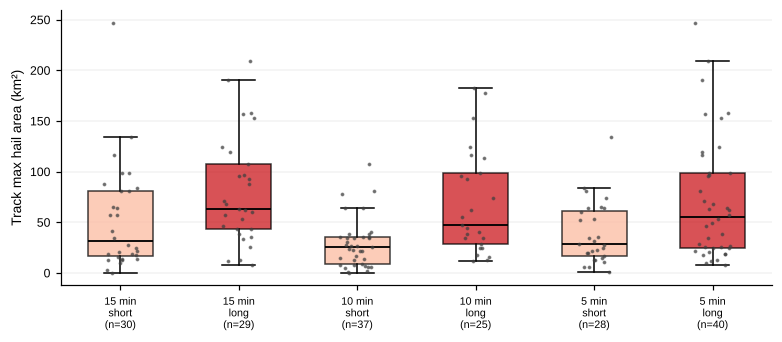

→ พื้นที่ลูกเห็บต่างกันอย่างมีนัยสำคัญที่ Δt = [15, 10, 5] ; สัดส่วนลูกเห็บที่ Δt = [10]
  พื้นที่ (km²) เพิ่มตามอายุชัดเจนและสม่ำเสมอกว่า เพราะพายุอายุยาวมักใหญ่ (size effect)
  สัดส่วน (fraction) ตัดผลของขนาดออก — ผลไม่สม่ำเสมอข้าม Δt แปลว่า 'ความเข้มข้น' ของลูกเห็บอาจไม่ได้ขึ้นกับอายุ


In [9]:
#@title ✅ เฉลยแบบฝึกหัด 4.1
from scipy.stats import mannwhitneyu
rows = []
for dt in (15, 10, 5):
    T = SETS[dt]["T"]
    lg = T.life_class.astype(str).str.startswith("long")
    for v in ("hail_col_km2", "hail_low_frac"):
        a, b = T.loc[lg, v].dropna(), T.loc[~lg, v].dropna()
        p = mannwhitneyu(a, b)[1] if len(a) > 2 and len(b) > 2 else np.nan
        rows.append({"dt_min": dt, "variable": v, "median_long": a.median(), "median_short": b.median(),
                     "cliffs_delta": tt.cliffs_delta(a, b), "p": p, "n_long": len(a), "n_short": len(b)})
print(pd.DataFrame(rows).set_index(["variable", "dt_min"]).round(3))
ALL = pd.concat([SETS[d]["T"].assign(dt=f"{d} min") for d in (15, 10, 5)])
ALL["grp"] = pd.Categorical(ALL["dt"] + "\n" + ALL["life_class"].astype(str).str.split(" ").str[0],
                            [f"{d} min\n{l}" for d in (15, 10, 5) for l in ("short", "long")])
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
tt.boxplot_groups(ax, ALL, "hail_col_km2", "grp", colors=["#fcbba1", "#cb181d"] * 3, ylabel="Track max hail area (km²)")
ax.tick_params(axis="x", labelsize=7)
mp.save_figure(fig, "nb4_ex41_hail_lifeclass")
plt.show()
r_ = pd.DataFrame(rows)
sig_area = r_[(r_.variable == "hail_col_km2") & (r_.p < 0.05)].dt_min.tolist()
sig_frac = r_[(r_.variable == "hail_low_frac") & (r_.p < 0.05)].dt_min.tolist()
print(f"→ พื้นที่ลูกเห็บต่างกันอย่างมีนัยสำคัญที่ Δt = {sig_area} ; สัดส่วนลูกเห็บที่ Δt = {sig_frac if sig_frac else 'ไม่มี'}")
print("  พื้นที่ (km²) เพิ่มตามอายุชัดเจนและสม่ำเสมอกว่า เพราะพายุอายุยาวมักใหญ่ (size effect)"
      "\n  สัดส่วน (fraction) ตัดผลของขนาดออก — ผลไม่สม่ำเสมอข้าม Δt แปลว่า 'ความเข้มข้น' ของลูกเห็บอาจไม่ได้ขึ้นกับอายุ")

### 🧪 แบบฝึกหัด 4.2: ลูกเห็บเกิดก่อน outflow หรือไม่ (ระดับเส้นทาง)?
สำหรับแต่ละเส้นทางอายุ ≥ 45 นาที (Δt = 5 นาที, ภาพจริงเท่านั้น) หาเวลาที่ `hail_col_km2` สูงสุด และเวลาที่ `dV` สูงสุด
แล้วคำนวณ lag = t(dV สูงสุด) − t(hail สูงสุด) เป็นนาที พลอต histogram

**คำถาม:** lag ส่วนใหญ่เป็นบวก (outflow ตามหลังลูกเห็บ) หรือไม่? ความละเอียด 15 นาทีของข้อมูลจริงจำกัดการตีความอย่างไร

<details>
<summary><b>💡 คำใบ้</b></summary>

- `for k, g in COMP[5].groupby("track_id"):` แล้ว `g.loc[g.hail_col_km2.idxmax(), "time"]`
- ข้ามเส้นทางที่ hail สูงสุด = 0

</details>

In [10]:
# ✍️ แบบฝึกหัด 4.2 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb4_ex42_hail_outflow_lag.png, figures/nb4_ex42_hail_outflow_lag.pdf


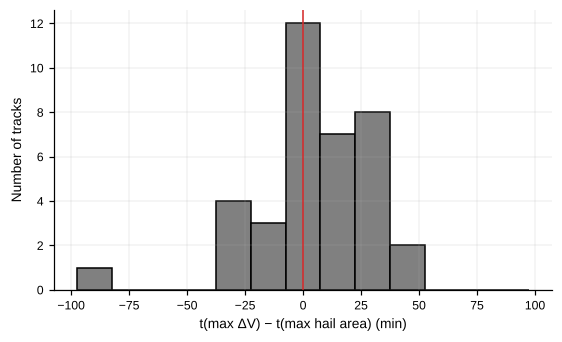

เส้นทางที่ใช้ได้: 37 | lag มัธยฐาน = +0 นาที | บวก 46%, ศูนย์ 32%, ลบ 22%
→ ข้อมูลจริงทุก 15 นาที ทำให้ lag เป็นจำนวนเท่าของ 15 นาทีเท่านั้น และ lag = 0 พบบ่อย (เกิดในภาพเดียวกัน)
  downburst มีอายุ 5–15 นาที อาจเกิดแล้วจบระหว่างสองภาพ → ต้องใช้ข้อมูลที่ถี่จริงหรือเรดาร์หลายตัวเพื่อยืนยัน


In [11]:
#@title ✅ เฉลยแบบฝึกหัด 4.2
lags = []
for k, g in COMP[5].groupby("track_id"):
    g = g.dropna(subset=["hail_col_km2", "dV"])
    if len(g) < 3 or g.hail_col_km2.max() <= 0:
        continue
    lags.append({"track_id": k, "lag_min": (g.loc[g.dV.idxmax(), "time"] - g.loc[g.hail_col_km2.idxmax(), "time"]).total_seconds() / 60,
                 "life": SETS[5]["T"].loc[k, "lifetime_min"]})
lags = pd.DataFrame(lags)
fig, ax = plt.subplots(figsize=(5, 3), layout="constrained")
ax.hist(lags.lag_min, bins=np.arange(-97.5, 98, 15), color="0.5", edgecolor="k")
ax.axvline(0, color="tab:red", lw=1)
ax.set_xlabel("t(max ΔV) − t(max hail area) (min)"); ax.set_ylabel("Number of tracks"); ax.grid(lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb4_ex42_hail_outflow_lag")
plt.show()
print(f"เส้นทางที่ใช้ได้: {len(lags)} | lag มัธยฐาน = {lags.lag_min.median():+.0f} นาที | "
      f"บวก {np.mean(lags.lag_min > 0):.0%}, ศูนย์ {np.mean(lags.lag_min == 0):.0%}, ลบ {np.mean(lags.lag_min < 0):.0%}")
print("→ ข้อมูลจริงทุก 15 นาที ทำให้ lag เป็นจำนวนเท่าของ 15 นาทีเท่านั้น และ lag = 0 พบบ่อย (เกิดในภาพเดียวกัน)"
      "\n  downburst มีอายุ 5–15 นาที อาจเกิดแล้วจบระหว่างสองภาพ → ต้องใช้ข้อมูลที่ถี่จริงหรือเรดาร์หลายตัวเพื่อยืนยัน")

### 🧪 แบบฝึกหัด 4.3: ความยาวเส้นทาง–KDP/EDR หลังควบคุมระยะจากเรดาร์
ที่ Δt = 15 และ 5 นาที คำนวณ Spearman ρ ระหว่าง `path_km` กับ `KDP95` และ `EDR95`
แล้วคำนวณ **partial ρ โดยควบคุม `beam_h_km`** (ความสูงลำคลื่นเฉลี่ยตามเส้นทาง) ด้วย `tt.partial_spearman`

**คำถาม:** ความสัมพันธ์ใดคงอยู่หลังควบคุมความสูงลำคลื่น? ทำไมความสูงลำคลื่นจึงเป็นตัวแปรแทรกซ้อนที่สำคัญของเรดาร์ 4 มุมยก

<details>
<summary><b>💡 คำใบ้</b></summary>

- `spearmanr(T.path_km, T.KDP95, nan_policy="omit")`
- `tt.partial_spearman(T, "path_km", "KDP95", "beam_h_km")`

</details>

In [12]:
# ✍️ แบบฝึกหัด 4.3 — เขียนโค้ดของคุณที่นี่

In [13]:
#@title ✅ เฉลยแบบฝึกหัด 4.3
rows = []
for dt in (15, 5):
    T = SETS[dt]["T"]
    for y in ("KDP95", "EDR95"):
        r0, p0 = spearmanr(T.path_km, T[y], nan_policy="omit")
        r1, p1, n = tt.partial_spearman(T, "path_km", y, "beam_h_km")
        rb = spearmanr(T.beam_h_km, T[y], nan_policy="omit")[0]
        rows.append({"dt_min": dt, "y": y, "n": n, "rho": r0, "p": p0, "rho(y, beam_h)": rb, "partial_rho|beam_h": r1, "partial_p": p1})
print(pd.DataFrame(rows).set_index(["y", "dt_min"]).round(3))
print("\n→ EDR95 สัมพันธ์เชิงลบกับความสูงลำคลื่นมาก (|ρ| ~0.8) — เมื่อควบคุมแล้ว ρ(path, EDR) กลับ 'ชัดขึ้น' (ตัวแปรแทรกซ้อนบดบังความสัมพันธ์)"
      "\n  ถ้าตัวแปร y สัมพันธ์กับความสูงลำคลื่นมาก (คอลัมน์ rho(y, beam_h)) การควบคุมจะเปลี่ยน ρ ชัดเจน"
      "\n  เรดาร์ 4 มุมยกมองพายุไกลที่ระดับสูงเท่านั้น: KDP (น้ำเหลว) ลดลง, EDR อาจเปลี่ยนตามระดับความสูง → ต้องควบคุมเสมอก่อนสรุปเชิงฟิสิกส์")

               n    rho      p  rho(y, beam_h)  partial_rho|beam_h  partial_p
y     dt_min                                                                 
KDP95 15      59  0.295  0.023          -0.447               0.345      0.008
EDR95 15      55  0.221  0.105          -0.788               0.329      0.014
KDP95 5       68  0.460  0.000          -0.434               0.478      0.000
EDR95 5       62  0.220  0.085          -0.841               0.247      0.053

→ EDR95 สัมพันธ์เชิงลบกับความสูงลำคลื่นมาก (|ρ| ~0.8) — เมื่อควบคุมแล้ว ρ(path, EDR) กลับ 'ชัดขึ้น' (ตัวแปรแทรกซ้อนบดบังความสัมพันธ์)
  ถ้าตัวแปร y สัมพันธ์กับความสูงลำคลื่นมาก (คอลัมน์ rho(y, beam_h)) การควบคุมจะเปลี่ยน ρ ชัดเจน
  เรดาร์ 4 มุมยกมองพายุไกลที่ระดับสูงเท่านั้น: KDP (น้ำเหลว) ลดลง, EDR อาจเปลี่ยนตามระดับความสูง → ต้องควบคุมเสมอก่อนสรุปเชิงฟิสิกส์


---
## 📝 สรุป
- ค่า HID, dual-pol และ Doppler ภายในเซลล์ดึงจากภาพจริงทุก 15 นาที — ภาพสังเคราะห์ใช้เพียงนิยามเส้นทางและอายุ
- composite ตามวงจรชีวิตช่วยดูลำดับเหตุการณ์ (ลูกเห็บ → outflow) แต่ความละเอียด 15 นาทีจำกัดการระบุ lag
- ตัวแปรเชิง "พื้นที่" (เช่น hail area) สัมพันธ์กับขนาดและอายุ ขณะที่ตัวแปรเชิง "สัดส่วน" ตัดผลของขนาดออก
- ความสัมพันธ์ที่เชื่อถือได้ควร **เห็นทุก Δt** และ **คงอยู่หลังควบคุมความสูงลำคลื่น**

### ❓ คำถามชวนคิด
1. ถ้า graupel ในระดับบนเพิ่มขึ้นก่อนลูกเห็บที่ระดับล่าง 15–30 นาที จะใช้เป็นสัญญาณเตือนล่วงหน้าได้หรือไม่? ต้องมีหลักฐานอะไรเพิ่ม
2. ทำไม ΔV จึงอาจสูงในพายุที่ไม่มี downburst? (คำใบ้: rotation, storm motion, ระยะใกล้เรดาร์)
3. ถ้าเพิ่มข้อมูลฟ้าผ่า (lightning) จะทดสอบความสัมพันธ์กับ graupel_up_frac อย่างไร

**🚀 ต่อยอด (ป.โท):** สร้าง **storm severity index** ระดับเส้นทาง จาก hail area, KDP95, ΔV, EDR95 (เช่น PCA หรือผลรวมอันดับ) แล้วทดสอบว่าเส้นทางที่ index สูงผ่านจุดรายงานความเสียหาย (NB2) มากกว่าหรือไม่

### 📚 เอกสารอ้างอิง
- Besic, N., et al. (2016). Hydrometeor classification through statistical clustering of polarimetric radar measurements: a semi-supervised approach. *Atmos. Meas. Tech.*, 9, 4425–4445.
- Kumjian, M. R. (2013). Principles and applications of dual-polarization weather radar. Part I–III. *J. Operational Meteor.*, 1, 226–274.
- Wilson, J. W., Roberts, R. D., Kessinger, C., & McCarthy, J. (1984). Microburst wind structure and evaluation of Doppler radar for airport wind shear detection. *J. Climate Appl. Meteor.*, 23, 898–915.
- Williams, J. K., & Meymaris, G. (2016). Remote turbulence detection using ground-based Doppler weather radar. In *Aviation Turbulence* (pp. 149–177). Springer.
- Byers, H. R., & Braham, R. R. (1949). *The Thunderstorm*. U.S. Government Printing Office.